In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.manifold import TSNE
import numpy as np
import seaborn as sns

In [ ]:
# def visualize_solutions(solutions, alpha):
#     # 'solutions' is a numpy array of shape (num_sols, N)
#     data = np.array(solutions)
    
#     # Project to 2D
#     tsne = TSNE(n_components=2, perplexity=min(30, len(data)-1), random_state=42)
#     embedded = tsne.fit_transform(data)
    
#     plt.scatter(embedded[:, 0], embedded[:, 1], s=5, alpha=0.5)
#     plt.title(f"Solution Space Structure at alpha={alpha}")
#     plt.show()

In [11]:
df = pd.read_csv("../results/solution_space_coords.csv")
df.head()

,Unnamed: 0,x,y,alpha
0,0,6.982420,8.317126,3.8
1,1,7.096528,8.179644,3.8
2,2,7.335303,7.883528,3.8
3,3,7.420121,7.396219,3.8
4,4,7.333060,4.670315,3.8


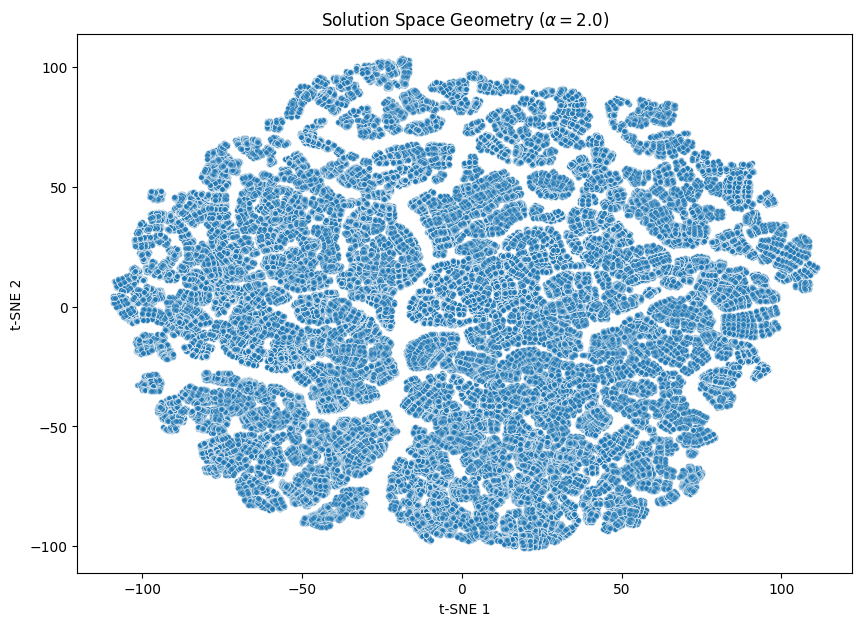

In [5]:
# Load the data
df = pd.read_csv("../results/solution_space_coords.csv")

# Filter for alpha 2.0 if you have multiple
df_alpha = df[df['alpha'] == 2.0]

plt.figure(figsize=(10, 7))
sns.scatterplot(data=df_alpha, x='x', y='y', alpha=0.5, s=15)
# plt.scatter(df_alpha['x'], df_alpha['y'], alpha=0.5, s=15)
plt.title("Solution Space Geometry ($\\alpha = 2.0$)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

Alphas found in CSV: [2.  3.  3.8 4. ]


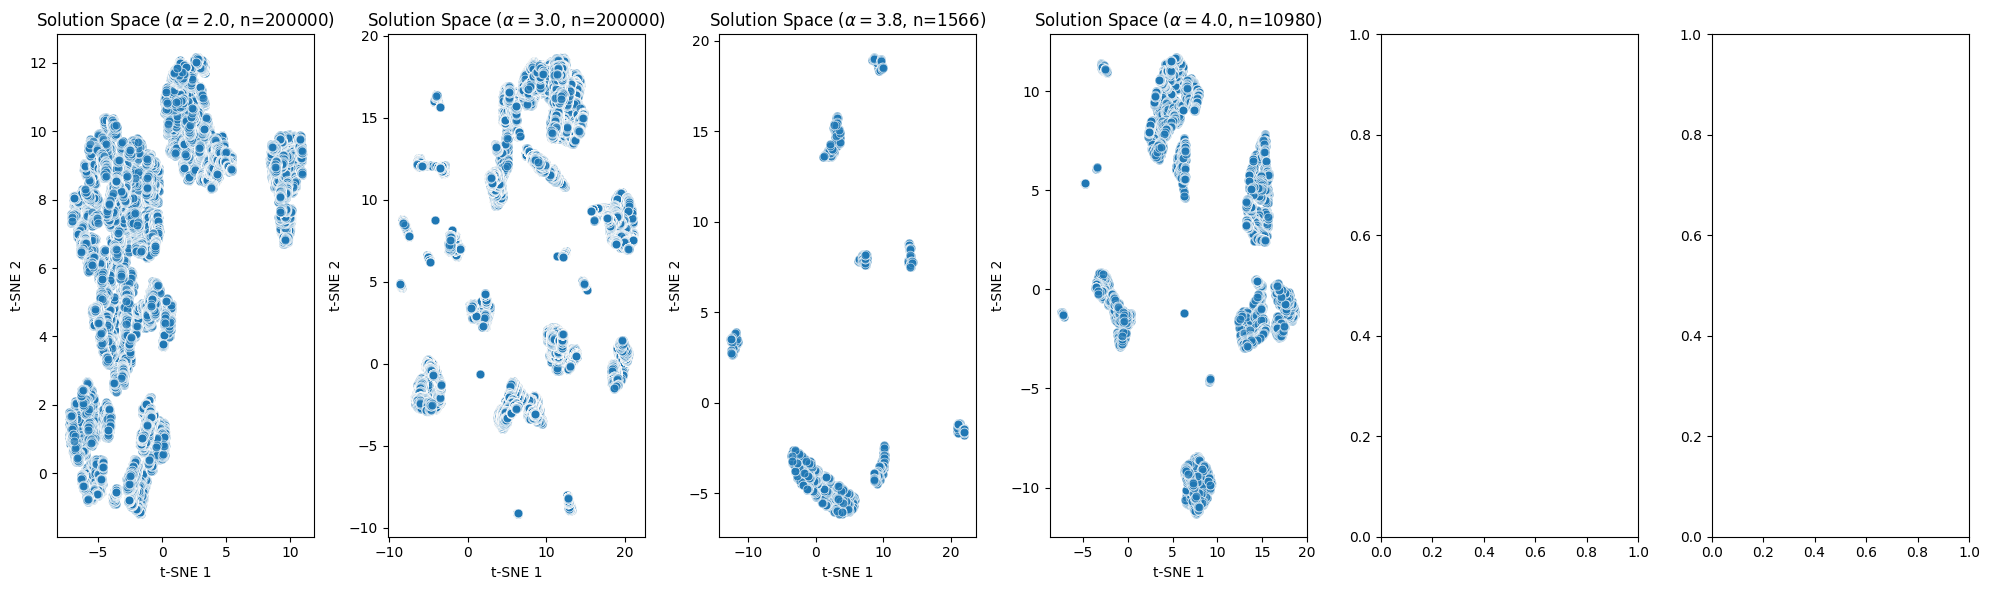

In [3]:
# Load the data (assuming you combined them or have the 3.8 file)
df = pd.read_csv("../results/solution_space_coords_N=50.csv") 

# Check what alphas are actually in the file to avoid empty plots
print("Alphas found in CSV:", df['alpha'].unique())

# Set up a side-by-side comparison
fig, axes = plt.subplots(1, 6, figsize=(20, 6))

for i, a in enumerate(df['alpha'].unique()[:6]): # Plot the first six alphas found
    subset = df[df['alpha'] == a]
    sns.scatterplot(data=subset, x='x', y='y', alpha=0.7, s=40, ax=axes[i])
    # sns.kdeplot(x=subset['x'], y=subset['y'], fill=True, ax=axes[i], cmap="viridis", thresh=0.05)
    axes[i].set_title(f"Solution Space ($\\alpha = {a}$, n={len(subset)})")
    axes[i].set_xlabel("t-SNE 1")
    axes[i].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()


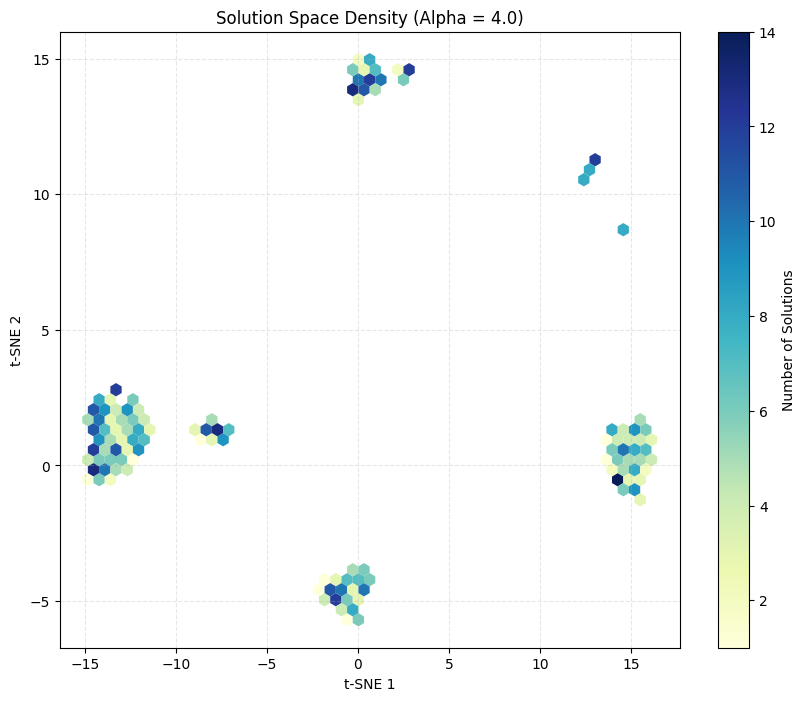

In [13]:
# import seaborn as sns
# from scipy.spatial.distance import pdist, squareform

# # Assuming 'subset' is your alpha = 4.1 dataframe with the raw solution bits
# # If you only have x,y coords, we can't do this - you'd need the raw 0/1 vectors
# def plot_hamming_heatmap(solutions, alpha):
#     distances = squareform(pdist(solutions, metric='cityblock'))
#     plt.figure(figsize=(8, 6))
#     sns.heatmap(distances, annot=True, cmap="YlGnBu")
#     plt.title(f"Pairwise Hamming Distances at $\\alpha = {alpha}$")
#     plt.show()


def plot_hexbin_space(df, alpha_val):
    subset = df[df['alpha'] == alpha_val]
    
    plt.figure(figsize=(10, 8))
    
    # gridsize: higher means more detail/smaller hexagons
    # mincnt=1: prevents plotting hexagons where there are 0 solutions
    hb = plt.hexbin(subset['x'], subset['y'], 
                    gridsize=50, 
                    cmap='YlGnBu', 
                    mincnt=1, 
                    edgecolors='none')
    
    cb = plt.colorbar(hb)
    cb.set_label('Number of Solutions')
    
    plt.title(f"Solution Space Density (Alpha = {alpha_val})")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.show()

# Example usage:
plot_hexbin_space(df, 4.0)
